# Notebook 01 — EDA: Base Model
**Question:** What does the raw system do, and where does the edge live?

**Hypothesis (pre-registered):**  
The base system (4-year file, unfiltered) has a positive but small expectancy (< 0.15 R) driven by a 2:1 reward-risk ratio. Edge is concentrated in specific sessions (London/NY overlap) and may degrade over time.

**Threats to validity:** single instrument, backtest spread assumptions, look-ahead in zone labels.

**Data:** `DATA/base_ml_4yr_processed.csv` — train + val splits only for analysis; holdout reported separately.

In [ ]:
import json, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
# %matplotlib inline

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

df = pd.read_csv('../DATA/base_ml_4yr_processed.csv', parse_dates=['open_time','close_time'])
df = df.sort_values('open_time').reset_index(drop=True)

# Splits
train_val = df[df['split'].isin(['train','val'])].copy()
holdout   = df[df['split'] == 'holdout'].copy()
print(f'Train+Val: {len(train_val):,} trades | Holdout: {len(holdout):,} trades')
print(f'Date range (train+val): {train_val.open_time.min().date()} → {train_val.open_time.max().date()}')
print(f'Date range (holdout)  : {holdout.open_time.min().date()} → {holdout.open_time.max().date()}')

Train+Val: 2,491 trades | Holdout: 549 trades
Date range (train+val): 2022-01-04 → 2025-11-28
Date range (holdout)  : 2025-12-01 → 2026-09-22


## 1. Headline Statistics

In [2]:
def headline_stats(df, label=''):
    n       = len(df)
    wins    = (df['result_R'] > 0).sum()
    wr      = wins / n
    exp_r   = df['result_R'].mean()
    winners = df.loc[df['result_R'] > 0, 'result_R']
    losers  = df.loc[df['result_R'] < 0, 'result_R']
    pf      = winners.sum() / abs(losers.sum()) if len(losers) else np.nan

    # 95% CI on win rate (Wilson)
    z = 1.96
    denom = 1 + z**2/n
    p_hat = wr
    ci_lo = (p_hat + z**2/(2*n) - z*np.sqrt(p_hat*(1-p_hat)/n + z**2/(4*n**2))) / denom
    ci_hi = (p_hat + z**2/(2*n) + z*np.sqrt(p_hat*(1-p_hat)/n + z**2/(4*n**2))) / denom

    # Equity curve & drawdown
    eq  = df['result_R'].cumsum()
    dd  = eq - eq.cummax()
    mdd = dd.min()

    print(f'=== {label} ===')
    print(f'  Trades         : {n:,}')
    print(f'  Win rate       : {wr:.3f}  95% CI [{ci_lo:.3f}, {ci_hi:.3f}]')
    print(f'  Expectancy     : {exp_r:+.4f} R')
    print(f'  Profit Factor  : {pf:.3f}')
    print(f'  Max Drawdown   : {mdd:.3f} R')
    print(f'  Total R        : {eq.iloc[-1]:+.2f} R')
    return dict(n=n, wr=wr, ci_lo=ci_lo, ci_hi=ci_hi,
                exp_r=exp_r, pf=pf, mdd=mdd, total_r=eq.iloc[-1])

stats_tv  = headline_stats(train_val, 'Train+Val')
print()
stats_ho  = headline_stats(holdout,   'Holdout')

=== Train+Val ===
  Trades         : 2,491
  Win rate       : 0.363  95% CI [0.344, 0.382]
  Expectancy     : +0.0824 R
  Profit Factor  : 1.128
  Max Drawdown   : -92.793 R
  Total R        : +205.16 R

=== Holdout ===
  Trades         : 549
  Win rate       : 0.348  95% CI [0.309, 0.389]
  Expectancy     : +0.0336 R
  Profit Factor  : 1.050
  Max Drawdown   : -42.972 R
  Total R        : +18.42 R


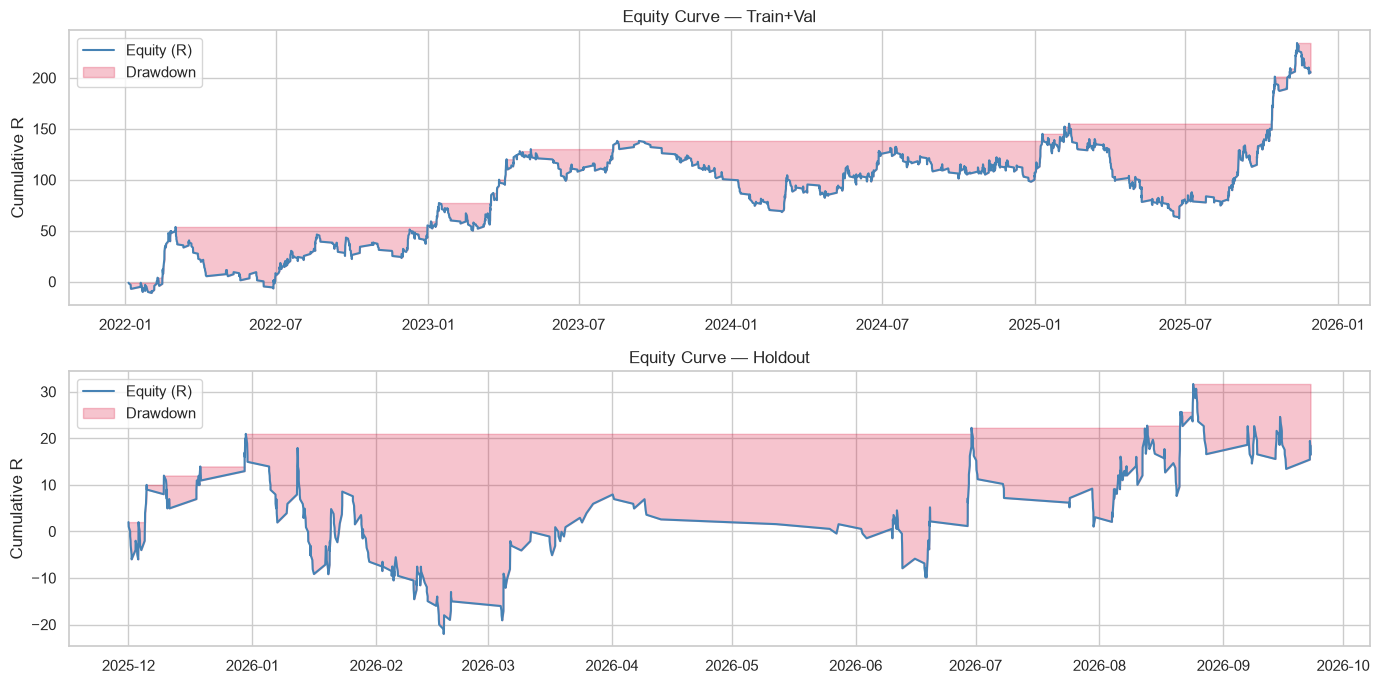

In [4]:
# Equity curve
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

for ax, (lbl, dset) in zip(axes, [('Train+Val', train_val), ('Holdout', holdout)]):
    eq = dset['result_R'].cumsum().reset_index(drop=True)
    dd = (eq - eq.cummax())
    ax.plot(dset['open_time'].values, eq.values, lw=1.5, color='steelblue', label='Equity (R)')
    ax.fill_between(dset['open_time'].values, eq.values, eq.cummax().values,
                    alpha=0.25, color='crimson', label='Drawdown')
    ax.set_title(f'Equity Curve — {lbl}')
    ax.set_ylabel('Cumulative R')
    ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig('../DATA/01_equity_curve.png', dpi=120)
plt.show()

## 2. Breakdowns: Signal, Side, Session, Weekday, Volatility Regime

In [5]:
def breakdown_table(df, by_col):
    tbl = df.groupby(by_col).agg(
        trades    = ('result_R','count'),
        win_rate  = ('win','mean'),
        exp_R     = ('result_R','mean'),
        total_R   = ('result_R','sum'),
        std_R     = ('result_R','std'),
    ).round(4)
    winners = df[df['result_R']>0].groupby(by_col)['result_R'].sum()
    losers  = df[df['result_R']<0].groupby(by_col)['result_R'].sum().abs()
    tbl['profit_factor'] = (winners / losers).round(3)
    return tbl.sort_values('exp_R', ascending=False)

# Session label
def session_label(hour):
    if 0 <= hour < 8:   return 'Asian'
    if 8 <= hour < 13:  return 'London'
    if 13 <= hour < 17: return 'NY/London'
    return 'NY'

train_val['session'] = train_val['open_hour'].apply(session_label)

# Volatility regime via ATR quartile
train_val['vol_regime'] = pd.qcut(train_val['atr_h1_pips'], 4,
                                   labels=['Low','Med-Low','Med-High','High'])

print('=== By Signal ===')
display(breakdown_table(train_val, 'signal'))
print('\n=== By Direction (Side) ===')
display(breakdown_table(train_val, 'direction'))
print('\n=== By Session ===')
display(breakdown_table(train_val, 'session'))
print('\n=== By Weekday ===')
display(breakdown_table(train_val, 'entry_day'))
print('\n=== By Volatility Regime ===')
display(breakdown_table(train_val, 'vol_regime'))

=== By Signal ===


,trades,win_rate,exp_R,total_R,std_R,profit_factor
signal,,,,,,
SIG_TYPE5_M30,372,0.3898,0.1675,62.320,1.4684,1.273
SIG_TYPE4_H1_M15,150,0.3800,0.1395,20.919,1.4633,1.224
SIG_BREAKER_M30,68,0.3676,0.1026,6.975,1.4596,1.162
SIG_TYPE5_H1_M15,197,0.3655,0.0959,18.898,1.4499,1.151
SIG_TYPE5_M15_M5,651,0.3641,0.0864,56.222,1.4609,1.134
SIG_TYPE4_M30,359,0.3593,0.0655,23.503,1.4716,1.100
SIG_TYPE4_M15_M3,510,0.3529,0.0470,23.993,1.4690,1.071
SIG_FAILEDENG_M30,184,0.3207,-0.0417,-7.673,1.4083,0.939



=== By Direction (Side) ===


,trades,win_rate,exp_R,total_R,std_R,profit_factor
direction,,,,,,
BUY,1581,0.3782,0.1250,197.606,1.4780,1.197
SELL,910,0.3363,0.0083,7.551,1.4246,1.012



=== By Session ===


,trades,win_rate,exp_R,total_R,std_R,profit_factor
session,,,,,,
NY,492,0.3984,0.1906,93.797,1.4851,1.312
Asian,741,0.3738,0.1112,82.387,1.4742,1.174
NY/London,592,0.3598,0.0793,46.924,1.4461,1.123
London,666,0.3273,-0.0270,-17.951,1.4317,0.961



=== By Weekday ===


,trades,win_rate,exp_R,total_R,std_R,profit_factor
entry_day,,,,,,
Mon,450,0.4156,0.2512,113.048,1.4897,1.429
Thu,502,0.3845,0.1507,75.669,1.4651,1.243
Wed,530,0.3547,0.0606,32.137,1.4425,1.093
Fri,480,0.3417,-0.0032,-1.524,1.4847,0.995
Tue,527,0.3264,-0.0231,-12.166,1.4121,0.966
Sun,2,0.0000,-1.0035,-2.007,0.0021,NaN



=== By Volatility Regime ===


,trades,win_rate,exp_R,total_R,std_R,profit_factor
vol_regime,,,,,,
Med-High,621,0.3671,0.1011,62.772,1.4498,1.159
High,623,0.3724,0.0948,59.085,1.5058,1.145
Med-Low,624,0.3622,0.0866,54.017,1.4477,1.135
Low,623,0.3499,0.0470,29.283,1.4367,1.072


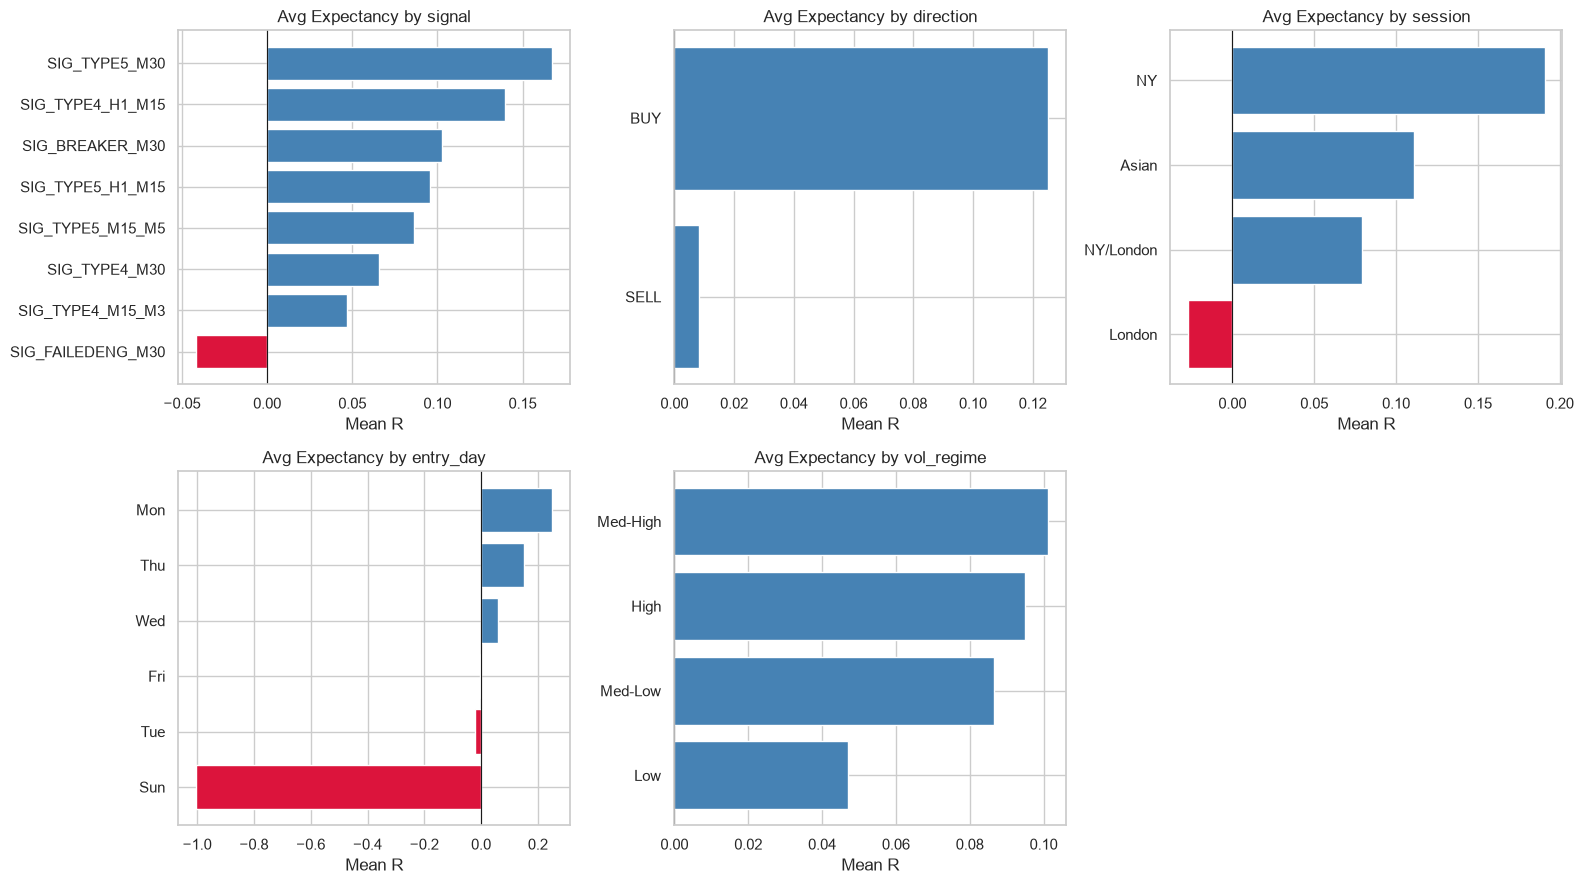

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, ['signal','direction','session','entry_day','vol_regime']):
    tbl = train_val.groupby(col)['result_R'].mean().sort_values()
    colors = ['crimson' if v < 0 else 'steelblue' for v in tbl.values]
    ax.barh(tbl.index, tbl.values, color=colors)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_title(f'Avg Expectancy by {col}')
    ax.set_xlabel('Mean R')

axes.flat[-1].axis('off')
plt.tight_layout()
plt.savefig('../DATA/01_breakdowns.png', dpi=120)
plt.show()

## 3. R Distribution & Streaks

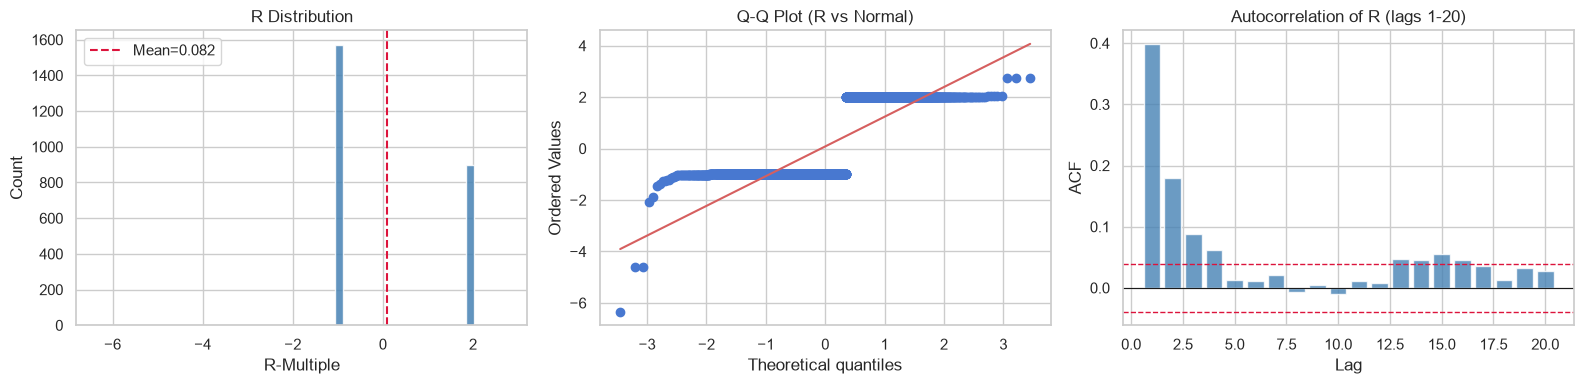

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# R histogram
ax = axes[0]
ax.hist(train_val['result_R'], bins=50, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(train_val['result_R'].mean(), color='crimson', ls='--', label=f'Mean={train_val["result_R"].mean():.3f}')
ax.set_title('R Distribution')
ax.set_xlabel('R-Multiple'); ax.set_ylabel('Count')
ax.legend()

# QQ plot
ax = axes[1]
stats.probplot(train_val['result_R'].dropna(), dist='norm', plot=ax)
ax.set_title('Q-Q Plot (R vs Normal)')

# Autocorrelation of R
ax = axes[2]
r_series = train_val['result_R'].values
lags = range(1, 21)
acf_vals = [pd.Series(r_series).autocorr(lag=k) for k in lags]
ax.bar(lags, acf_vals, color='steelblue', alpha=0.8)
ax.axhline(0, color='k', lw=0.8)
ax.axhline( 1.96/np.sqrt(len(r_series)), color='crimson', ls='--', lw=1)
ax.axhline(-1.96/np.sqrt(len(r_series)), color='crimson', ls='--', lw=1)
ax.set_title('Autocorrelation of R (lags 1-20)')
ax.set_xlabel('Lag'); ax.set_ylabel('ACF')

plt.tight_layout()
plt.savefig('../DATA/01_r_distribution.png', dpi=120)
plt.show()

In [8]:
# Losing streak analysis
def max_losing_streak(r_series):
    max_s, cur = 0, 0
    for r in r_series:
        if r < 0: cur += 1; max_s = max(max_s, cur)
        else: cur = 0
    return max_s

mls_tv = max_losing_streak(train_val['result_R'])
mls_ho = max_losing_streak(holdout['result_R'])
print(f'Max losing streak — Train+Val: {mls_tv}  |  Holdout: {mls_ho}')

# Tail stats
r = train_val['result_R']
print(f'\nLeft tail (1%):  {r.quantile(0.01):.3f} R')
print(f'Right tail (99%): {r.quantile(0.99):.3f} R')
print(f'Skewness: {r.skew():.3f}  |  Kurtosis: {r.kurt():.3f}')

Max losing streak — Train+Val: 32  |  Holdout: 17

Left tail (1%):  -1.013 R
Right tail (99%): 2.009 R
Skewness: 0.507  |  Kurtosis: -1.467


## 4. Stop & Target Quality — MAE / MFE

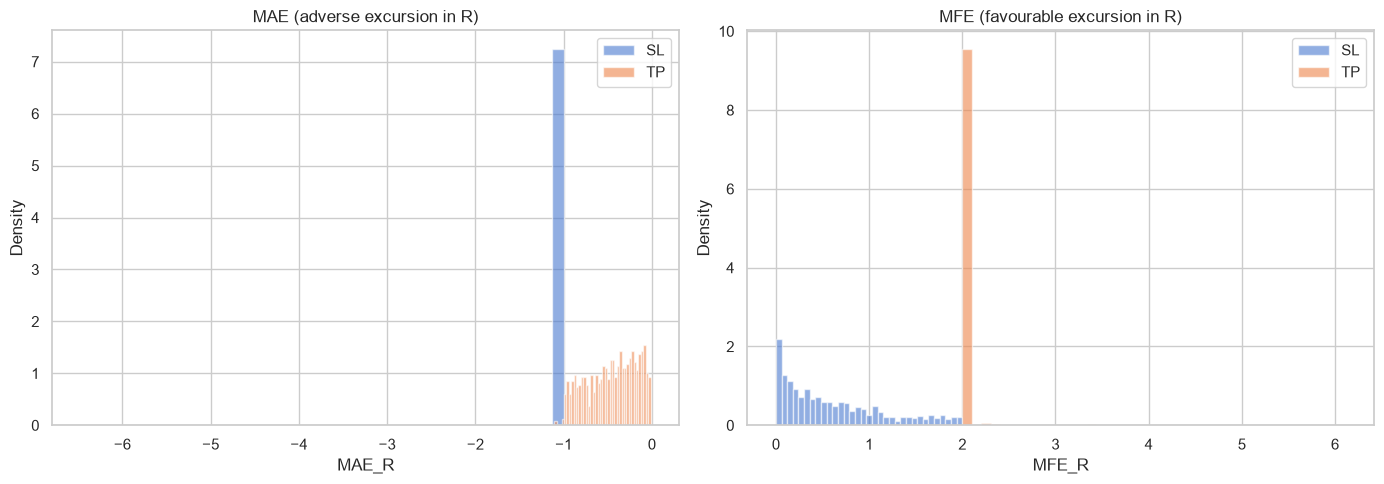

MAE (mean) by exit reason:
             MAE_R  MFE_R
exit_reason              
SL          -1.016  0.613
TP          -0.456  2.017


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, title in [
    (axes[0], 'MAE_R', 'MAE (adverse excursion in R)'),
    (axes[1], 'MFE_R', 'MFE (favourable excursion in R)')
]:
    for outcome, grp in train_val.groupby('exit_reason'):
        vals = grp[metric].dropna()
        ax.hist(vals, bins=40, alpha=0.6, label=outcome, density=True)
    ax.set_title(title); ax.set_xlabel(metric); ax.set_ylabel('Density')
    ax.legend()

plt.tight_layout()
plt.savefig('../DATA/01_mae_mfe.png', dpi=120)
plt.show()

print('MAE (mean) by exit reason:')
print(train_val.groupby('exit_reason')[['MAE_R','MFE_R']].mean().round(3))

## 5. Rolling Expectancy (Stability)

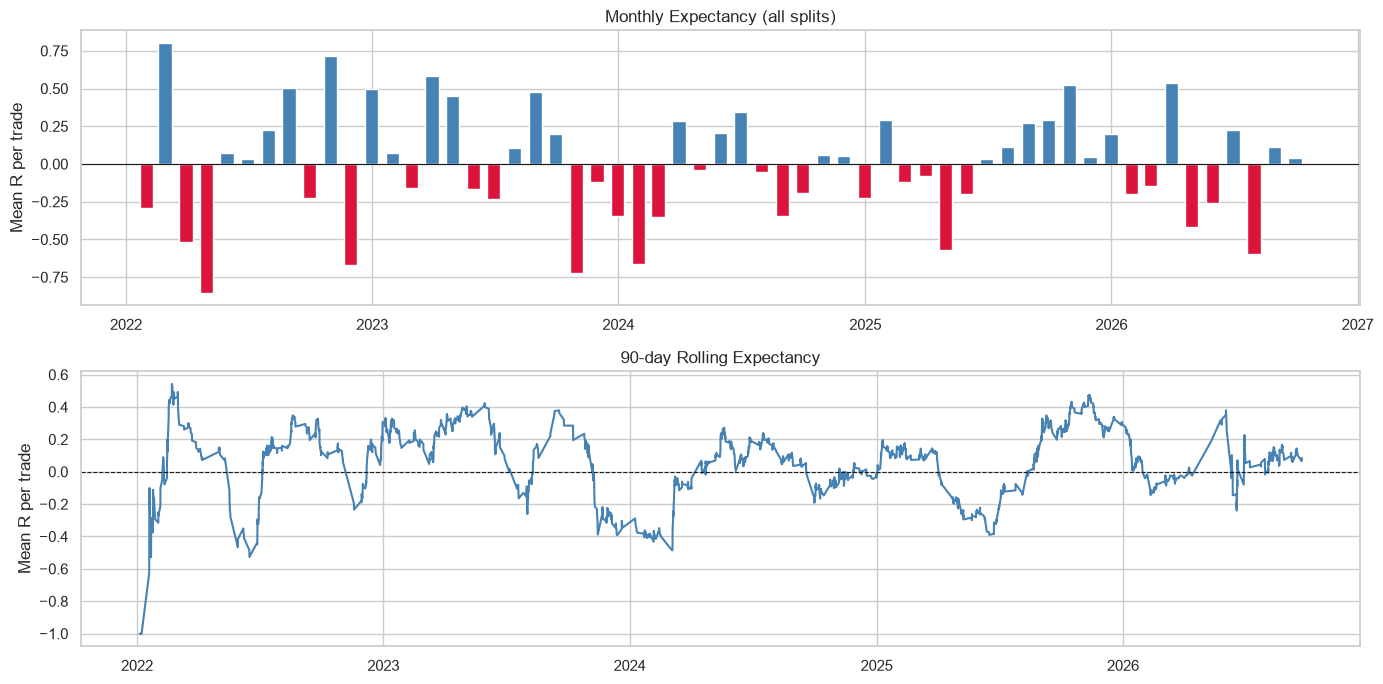

In [10]:
monthly_exp = (
    df.set_index('open_time')['result_R']
    .resample('ME').mean()
    .rename('monthly_exp_R')
)

rolling_exp = (
    df.set_index('open_time')['result_R']
    .rolling('90D').mean()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

axes[0].bar(monthly_exp.index, monthly_exp.values, width=20,
            color=['steelblue' if v >= 0 else 'crimson' for v in monthly_exp.values])
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_title('Monthly Expectancy (all splits)')
axes[0].set_ylabel('Mean R per trade')

axes[1].plot(rolling_exp.index, rolling_exp.values, color='steelblue', lw=1.5)
axes[1].axhline(0, color='k', ls='--', lw=0.8)
axes[1].set_title('90-day Rolling Expectancy')
axes[1].set_ylabel('Mean R per trade')

plt.tight_layout()
plt.savefig('../DATA/01_rolling_expectancy.png', dpi=120)
plt.show()

## 6. Edge Test — Bootstrap of Expectancy

Bootstrap (10,000 reps) — Expectancy (Train+Val)
  Observed: +0.08236 R
  95% CI  : [+0.02611, +0.13923]
  P(exp > 0): 0.9980


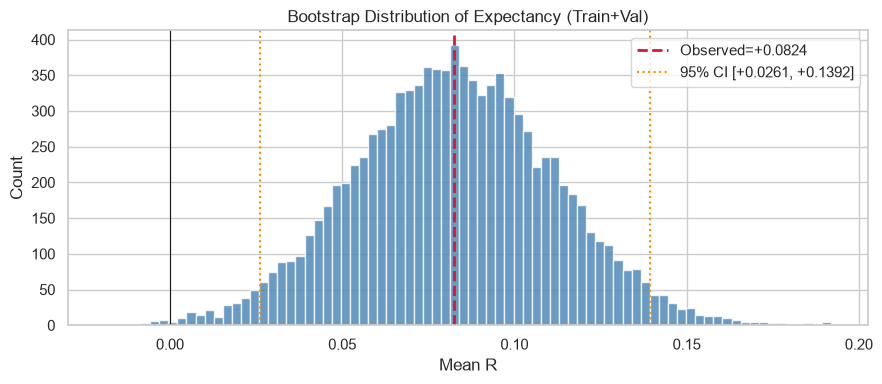

In [11]:
np.random.seed(RANDOM_SEED)
N_BOOT = 10_000
r_tv = train_val['result_R'].values

boot_means = [np.random.choice(r_tv, len(r_tv), replace=True).mean() for _ in range(N_BOOT)]
boot_means = np.array(boot_means)

ci_lo, ci_hi = np.percentile(boot_means, [2.5, 97.5])
p_above_zero = (boot_means > 0).mean()

print(f'Bootstrap ({N_BOOT:,} reps) — Expectancy (Train+Val)')
print(f'  Observed: {r_tv.mean():+.5f} R')
print(f'  95% CI  : [{ci_lo:+.5f}, {ci_hi:+.5f}]')
print(f'  P(exp > 0): {p_above_zero:.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(boot_means, bins=80, color='steelblue', edgecolor='white', alpha=0.8)
ax.axvline(r_tv.mean(), color='crimson', ls='--', lw=2, label=f'Observed={r_tv.mean():+.4f}')
ax.axvline(ci_lo, color='darkorange', ls=':', lw=1.5, label=f'95% CI [{ci_lo:+.4f}, {ci_hi:+.4f}]')
ax.axvline(ci_hi, color='darkorange', ls=':', lw=1.5)
ax.axvline(0, color='k', lw=0.8)
ax.set_title('Bootstrap Distribution of Expectancy (Train+Val)')
ax.set_xlabel('Mean R'); ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.savefig('../DATA/01_bootstrap_expectancy.png', dpi=120)
plt.show()

## 7. Holdout Summary (never tuned on)

=== Holdout (Dec 2025 → Sep 2026) ===
  Trades         : 549
  Win rate       : 0.348  95% CI [0.309, 0.389]
  Expectancy     : +0.0336 R
  Profit Factor  : 1.050
  Max Drawdown   : -42.972 R
  Total R        : +18.42 R


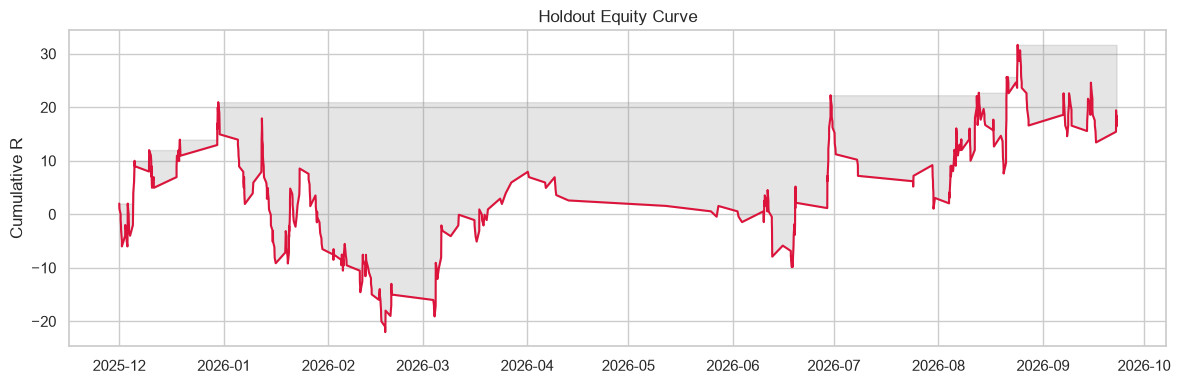

In [12]:
_ = headline_stats(holdout, 'Holdout (Dec 2025 → Sep 2026)')

fig, ax = plt.subplots(figsize=(12, 4))
eq_ho = holdout['result_R'].cumsum().reset_index(drop=True)
ax.plot(holdout['open_time'].values, eq_ho.values, lw=1.5, color='crimson')
ax.fill_between(holdout['open_time'].values, eq_ho.values, eq_ho.cummax().values,
                alpha=0.2, color='gray')
ax.set_title('Holdout Equity Curve'); ax.set_ylabel('Cumulative R')
plt.tight_layout()
plt.savefig('../DATA/01_holdout_equity.png', dpi=120)
plt.show()